In [2]:
import sys
!{sys.executable} -m pip install torch torchvision


In [3]:
# Imports:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os
import torch.nn as nn
import torch.optim as optim

In [4]:
import os
import kagglehub
from sklearn.model_selection import train_test_split

# 1. Download do dataset do Kaggle para o ambiente do Colab
path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")

# 2. Mapeamento de todos os arquivos de imagem no diretório baixado
all_files = []
for root, _, files in os.walk(path):
    for file in files:
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            all_files.append(os.path.join(root, file))

# 3. Divisão aleatória em Treino (80%), Validação (10%) e Teste (10%)
train_files, temp_files = train_test_split(all_files, test_size=0.20, shuffle=True)
val_files, test_files = train_test_split(temp_files, test_size=0.50, shuffle=True)

print(f"Total de imagens encontradas: {len(all_files)}")
print(f"Conjunto de Treino (80%): {len(train_files)}")
print(f"Conjunto de Validação (10%): {len(val_files)}")
print(f"Conjunto de Teste (10%): {len(test_files)}")

Total de imagens encontradas: 24998
Conjunto de Treino (80%): 19998
Conjunto de Validação (10%): 2500
Conjunto de Teste (10%): 2500


In [5]:
# 1. Redimensionamento e Normalização das imagens para 224x224
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Estrutura do Dataset para mapeamento de arquivos e rótulos
class CatDogDataset(Dataset):
    def __init__(self, file_paths, transform=None):
        self.file_paths = file_paths
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img_path = self.file_paths[idx]
        image = Image.open(img_path).convert("RGB")

        # verifica se a pasta pai imediata é "Dog"
        parent_dir = os.path.basename(os.path.dirname(img_path)).lower()
        label = 1.0 if parent_dir == "dog" else 0.0

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.float32)

# 3. Instanciação dos DataLoaders com tamanho de lote igual a 50
train_dataset = CatDogDataset(train_files, transform=transform)
val_dataset = CatDogDataset(val_files, transform=transform)
test_dataset = CatDogDataset(test_files, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=50, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=50, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=50, shuffle=False)

print(f"Lotes de treino: {len(train_loader)} | Lotes de validação: {len(val_loader)} | Lotes de teste: {len(test_loader)}")


Lotes de treino: 400 | Lotes de validação: 50 | Lotes de teste: 50


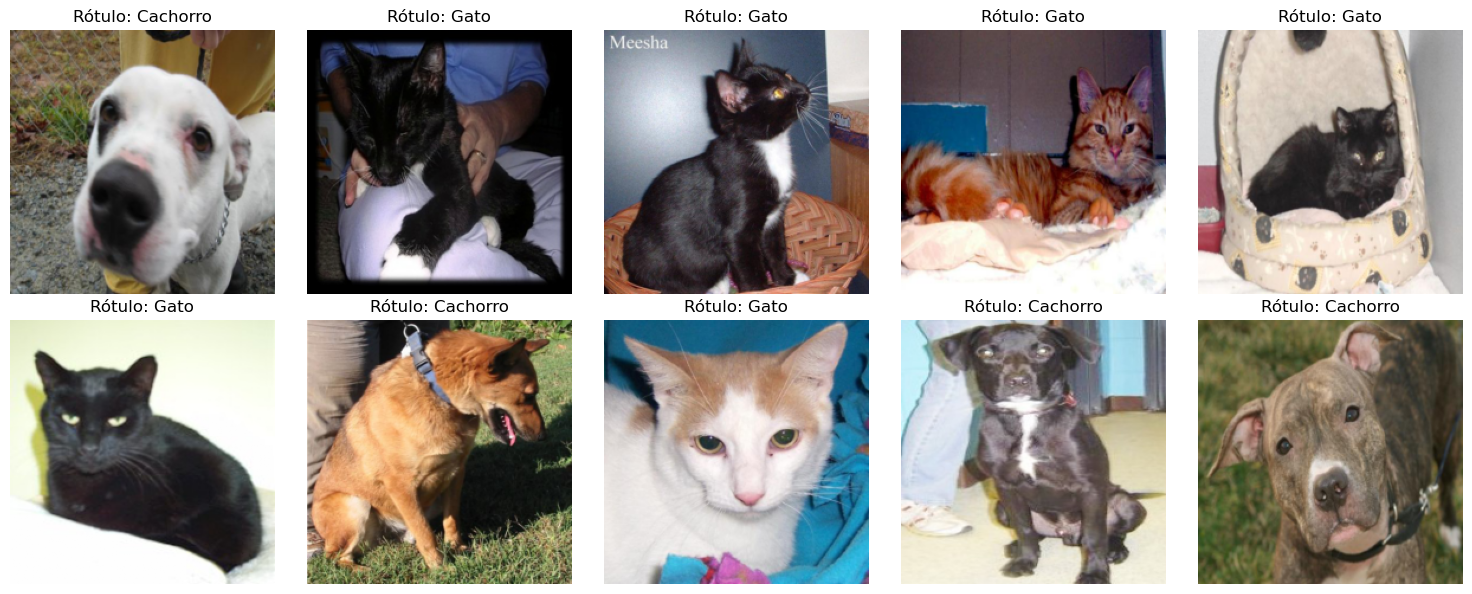

In [6]:
## Conferencia dos rótulos e imagens:
import torch
import matplotlib.pyplot as plt
import random
import numpy as np

num_amostras = 10
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
indices_aleatorios = random.sample(range(len(train_loader.dataset)), num_amostras)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i, idx in enumerate(indices_aleatorios):
    imagem_tensor, rotulo = train_loader.dataset[idx]
    classe_real = "Cachorro" if rotulo.item() == 1.0 else "Gato"
    # Desnormalizar para exibição com cores naturais
    imagem_numpy = imagem_tensor.permute(1, 2, 0).numpy()
    imagem_numpy = std * imagem_numpy + mean
    imagem_numpy = np.clip(imagem_numpy, 0, 1)
    
    axes[i].imshow(imagem_numpy)
    axes[i].set_title(f"Rótulo: {classe_real}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()


In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executando no dispositivo: {device}")

class AlexNetBinary(nn.Module):
    def __init__(self):
        super(AlexNetBinary, self).__init__()
        # Adicionado BatchNorm2d para estabilizar gradientes e acelerar o aprendizado
        self.features = nn.Sequential(
            nn.Conv2d(3, 96, kernel_size=11, stride=4, padding=2),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(96, 256, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2),

            nn.Conv2d(256, 384, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(384),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 384, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(384),
            nn.ReLU(inplace=True),

            nn.Conv2d(384, 256, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2)
        )
        self.classifier = nn.Sequential(
            nn.Linear(256 * 6 * 6, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),

            nn.Linear(4096, 4096),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),

            nn.Linear(4096, 1) # Sem Sigmoid: saída em logit para evitar saturação
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x.squeeze(-1) # Retorna tensor 1D de logits


Executando no dispositivo: cpu


In [9]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executando no dispositivo: {device}")

# Instanciação do modelo, função de perda BCEWithLogitsLoss e otimizador Adam (lr=1e-4)
model = AlexNetBinary().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# Parâmetros do treinamento e do Early Stopping
epochs = 40
patience = 5  # Número de épocas sem melhoria na perda de validação antes de parar
patience_counter = 0
best_val_loss = float("inf")
best_model_weights = None

results_history = []

print("==========================================")
print(" Treinamento AlexNetBinary (Adam lr=0.0001, BCEWithLogitsLoss)")
print("==========================================")

for epoch in range(1, epochs + 1):
    # --- FASE DE TREINAMENTO ---
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (inputs, targets) in enumerate(train_loader, start=1):
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)
        # Com logit, >= 0.0 corresponde a probabilidade >= 0.5
        predictions = (outputs >= 0.0).float()
        train_correct += (predictions == targets).sum().item()
        train_total += targets.size(0)

        running_loss = train_loss / train_total
        running_acc = (train_correct / train_total) * 100
        print(f"Época [{epoch:02d}/{epochs:02d}] - Lote [{batch_idx:03d}/{len(train_loader):03d}] | "
              f"Loss Lote: {loss.item():.4f} | Loss Médio: {running_loss:.4f} | Acc Média: {running_acc:.2f}%", end="", flush=True)

    print()  # Quebra de linha após finalizar os lotes de treino

    epoch_train_loss = train_loss / train_total
    epoch_train_acc = (train_correct / train_total) * 100
    epoch_train_err = 100.0 - epoch_train_acc

    # --- FASE DE VALIDAÇÃO ---
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for val_idx, (inputs, targets) in enumerate(val_loader, start=1):
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)

            val_loss += loss.item() * inputs.size(0)
            predictions = (outputs >= 0.0).float()
            val_correct += (predictions == targets).sum().item()
            val_total += targets.size(0)

            print(f"Validando... Lote [{val_idx:03d}/{len(val_loader):03d}]", end="", flush=True)

    print()  # Quebra de linha após a validação

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = (val_correct / val_total) * 100
    epoch_val_err = 100.0 - epoch_val_acc

    results_history.append({
        "epoch": epoch,
        "train_loss": epoch_train_loss,
        "train_acc": epoch_train_acc,
        "train_err": epoch_train_err,
        "val_loss": epoch_val_loss,
        "val_acc": epoch_val_acc,
        "val_err": epoch_val_err
    })

    print(f"-> Resumo Época {epoch:02d}/{epochs:02d} | "
          f"Treino - Loss: {epoch_train_loss:.4f}, Acc: {epoch_train_acc:.2f}% | "
          f"Val - Loss: {epoch_val_loss:.4f}, Acc: {epoch_val_acc:.2f}%")

    # --- VERIFICAÇÃO DO EARLY STOPPING ---
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1
        print(f"   -> Val Loss não melhorou ({patience_counter}/{patience})")
        if patience_counter >= patience:
            print(f"
Early Stopping ativado na época {epoch}!")
            print(f"Melhor Val Loss registrado: {best_val_loss:.4f}")
            break

# Restaura o estado com os melhores pesos obtidos na validação
if best_model_weights is not None:
    model.load_state_dict(best_model_weights)
    print("Pesos do melhor modelo restaurados com sucesso.")


Executando no dispositivo: cpu
 Treinamento AlexNetBinary (Adam, 40 Épocas, Early Stopping)


KeyboardInterrupt: 

In [ ]:
# Exportar o Histórico de Treinamento e Validação para CSV
import pandas as pd

if len(results_history) > 0:
    df_history = pd.DataFrame(results_history)
    arquivo_csv = "training_history_Lisandra.csv"
    df_history.to_csv(arquivo_csv, index=False)
    print(f"Sucesso! Histórico salvo em '{arquivo_csv}' com {len(df_history)} épocas registradas.")
    df_history
else:
    print("Aviso: 'results_history' está vazio. Execute a célula de treinamento para popular o histórico.")


In [ ]:
# 1. Gráficos de Perda e Acurácia ao longo das épocas
import matplotlib.pyplot as plt

epochs_range = [r["epoch"] for r in results_history]
train_losses = [r["train_loss"] for r in results_history]
val_losses = [r["val_loss"] for r in results_history]
train_accs = [r["train_acc"] for r in results_history]
val_accs = [r["val_acc"] for r in results_history]

plt.figure(figsize=(14, 5))

# Curva de Perda (Loss)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, train_losses, label="Treino Loss", marker="o")
plt.plot(epochs_range, val_losses, label="Validação Loss", marker="o")
plt.title("Evolução da Perda (Loss)")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Curva de Acurácia
plt.subplot(1, 2, 2)
plt.plot(epochs_range, train_accs, label="Treino Acurácia", marker="o")
plt.plot(epochs_range, val_accs, label="Validação Acurácia", marker="o")
plt.title("Evolução da Acurácia (%)")
plt.xlabel("Época")
plt.ylabel("Acurácia (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
# 2. Avaliação final no Conjunto de Teste
model.eval()
test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, targets)

        test_loss += loss.item() * inputs.size(0)
        predictions = (outputs >= 0.0).float()
        test_correct += (predictions == targets).sum().item()
        test_total += targets.size(0)

final_test_loss = test_loss / test_total
final_test_acc = (test_correct / test_total) * 100

print("==========================================")
print(" Resultado no Conjunto de Teste")
print("==========================================")
print(f"Loss Médio de Teste : {final_test_loss:.4f}")
print(f"Acurácia de Teste   : {final_test_acc:.2f}%")
print(f"Taxa de Erro        : {100.0 - final_test_acc:.2f}%")


In [ ]:
# 3. Visualização de predições em imagens do conjunto de teste
import random
import numpy as np
import matplotlib.pyplot as plt

model.eval()
num_amostras = 10
indices = random.sample(range(len(test_dataset)), num_amostras)

fig, axes = plt.subplots(2, 5, figsize=(16, 7))
axes = axes.flatten()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

with torch.no_grad():
    for i, idx in enumerate(indices):
        imagem_tensor, rotulo = test_dataset[idx]
        input_tensor = imagem_tensor.unsqueeze(0).to(device)
        logit = model(input_tensor).item()
        prob = torch.sigmoid(torch.tensor(logit)).item()
        pred_class = "Cachorro" if prob >= 0.5 else "Gato"
        real_class = "Cachorro" if rotulo.item() == 1.0 else "Gato"
        cor = "green" if pred_class == real_class else "red"

        # Desnormalizar para exibição com cores naturais
        img_numpy = imagem_tensor.permute(1, 2, 0).cpu().numpy()
        img_numpy = std * img_numpy + mean
        img_numpy = np.clip(img_numpy, 0, 1)

        axes[i].imshow(img_numpy)
        axes[i].set_title(f"Pred: {pred_class} ({prob:.2f})
Real: {real_class}", color=cor, fontsize=11)
        axes[i].axis("off")

plt.tight_layout()
plt.show()


In [ ]:
# 4. Salvar os pesos do melhor modelo treinado
caminho_modelo = "alexnet_cats_dogs_best.pth"
torch.save(model.state_dict(), caminho_modelo)
print(f"Modelo salvo com sucesso em '{caminho_modelo}'!")
